In [9]:
% some housekeeping stuff
clear
graphics_toolkit ("plotly")
warning off
format short e
% end of housekeeping

Using the equations derived in class solve for the titration curve of any diprotic acid with NaOH.
need to specify acid concentration, pKa1, pKa2, total volume and NaOH molarity.
INTERACTIONS
1) make 0.1 M initial total acid (line 2).  predict qualitatively how initial pH will change, and shape of equiv points.  also quantititavely predict 1/2 Ve1 and 1/2 Ve2 pH values.
2) make back to 0.01 M initial total acid (line 2) and change pKa1=4.3 and pKa2=8.3.  predict qualitatively how initial pH will change, and shape of equiv points.  also quantititavely predict 1/2 Ve1 and 1/2 Ve2 pH values.

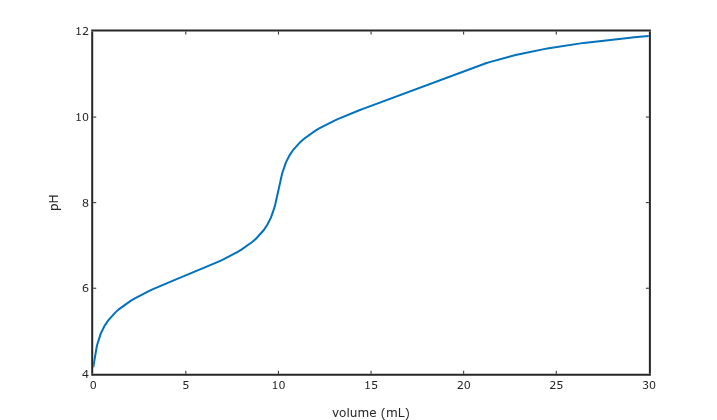

In [10]:
VT=0.1; % total volume in L
AT=0.01; % acid conc in M
pKa1=6.3; %pKa1
pKa2=10.3; %pKa2
concNaOH=0.1; %MOLARITY OF THE NaOH titrant

% the K values

Kw=1e-14; Ka1=10^-pKa1; Ka2=10^-pKa2;

% do this relative to equivaleant point volumes.

Ve1=(AT*VT)./concNaOH; Ve2=2*Ve1;
vol=0:Ve1/50:3*Ve1;

% now solve the cubic equation for H

for i=1:length(vol)
    Na=(vol(i)*concNaOH)./(VT+vol(i));
    CT=(VT*AT)./(VT+vol(i));
    a=1;
    b=Ka1+Na;
    c=Ka1*Ka2+Na*Ka1-Kw-CT*Ka1;
    d=Na*Ka1*Ka2-Kw*Ka1-2*CT*Ka1*Ka2;
    e=-Kw*Ka1*Ka2;
    t=roots([a b c d e]);
    t=t(imag(t)==0); %sets any imaginary roots to zero
    t=t(t>0);
    pH(i)=-log10(t);
end

plot(vol*1000,pH,'linewidth',2)
set(gca,'linewidth',2,'fontsize',11)
xlabel('volume (mL)'); ylabel('pH');